# test sur donnees reelles : UCI HAR (acceleration pendant la marche)

signal : acceleration corporelle body_acc_x a 50 Hz, activite = marche (label 1)

domaine = sujet : chaque personne a sa propre demarche (frequence de pas, amplitude)

source = sujet 25, cible = sujet 3 (les deux plus longs enregistrements continus)

le dataset fournit des fenetres de 128 echantillons avec 50% de recouvrement : deux fenetres consecutives d'une meme session partagent exactement 64 echantillons, ce qui permet de reconstruire le signal continu.


In [17]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

from adapt.feature_based import CORAL, SA, TCA, fMMD, FA
from adapt.instance_based import KMM, KLIEP, TrAdaBoostR2
from adapt.parameter_based import RegularTransferLR

from adapt_utils import sliding_window, evaluate_baseline, evaluate_adapt

## Chargement et reconstruction du signal continu

In [18]:
data_dir = "../../data/UCI HAR Dataset/train"

signals = np.loadtxt(f"{data_dir}/Inertial Signals/body_acc_x_train.txt")
subjects = np.loadtxt(f"{data_dir}/subject_train.txt", dtype=int)
activities = np.loadtxt(f"{data_dir}/y_train.txt", dtype=int)

signals.shape

(7352, 128)

In [19]:
def longest_contiguous_series(windows, half=64, tol=1e-6):
    joins = np.abs(windows[:-1, half:] - windows[1:, :half]).max(axis=1) < tol
    best_start, best_len, start, length = 0, 1, 0, 1
    for i, ok in enumerate(joins):
        if ok:
            length += 1
        else:
            start, length = i + 1, 1
        if length > best_len:
            best_start, best_len = start, length
    block = windows[best_start:best_start + best_len]
    return np.concatenate([block[0]] + [w[half:] for w in block[1:]])


def subject_walking_series(subject_id):
    mask = (subjects == subject_id) & (activities == 1)
    return longest_contiguous_series(signals[mask])

In [20]:
series_source = subject_walking_series(25)
series_target = subject_walking_series(3)

len(series_source), len(series_target)

(1408, 1088)

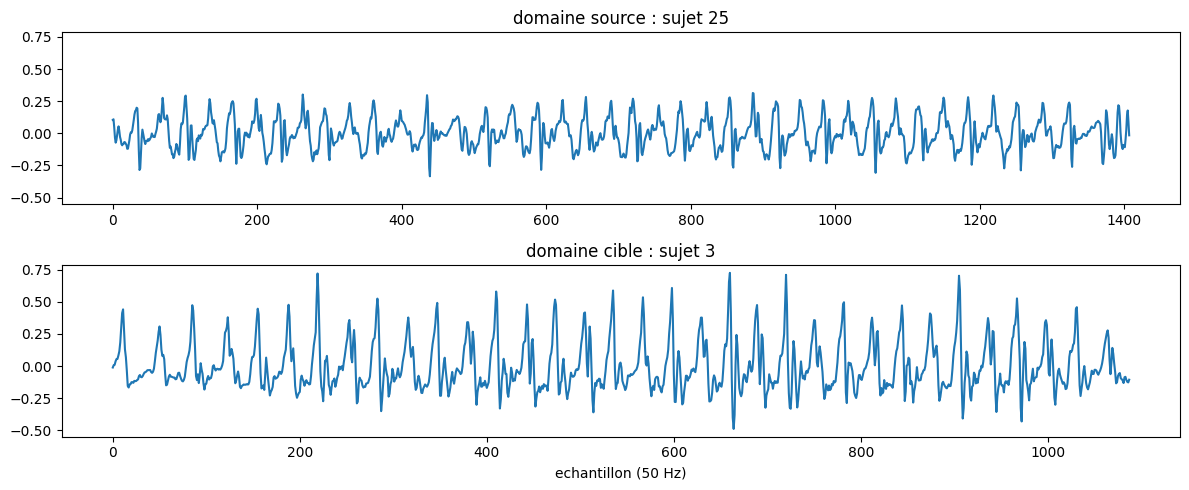

In [21]:
fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharey=True)
axes[0].plot(series_source)
axes[0].set_title("domaine source : sujet 25")
axes[1].plot(series_target)
axes[1].set_title("domaine cible : sujet 3")
axes[1].set_xlabel("echantillon (50 Hz)")
plt.tight_layout()
plt.show()

## Baseline et methodes ADAPT

In [22]:
window_size = 20
horizon = 1

Xt, yt = sliding_window(series_target, window_size, horizon)

results = []

metrics = evaluate_baseline(series_source, window_size, Xt, yt, LinearRegression(), horizon=horizon)
results.append(dict(method="sans adaptation", **metrics))

unsupervised_methods = {"CORAL": CORAL, "SA": SA, "TCA": TCA, "fMMD": fMMD, "KMM": KMM, "KLIEP": KLIEP}
for name, adapt_class in unsupervised_methods.items():
    metrics = evaluate_adapt(adapt_class, series_source, window_size, Xt, yt, LinearRegression(), horizon=horizon)
    results.append(dict(method=name, **metrics))

supervised_methods = {"FA": FA, "TrAdaBoostR2": TrAdaBoostR2}
for name, adapt_class in supervised_methods.items():
    metrics = evaluate_adapt(adapt_class, series_source, window_size, Xt, yt, LinearRegression(), use_target_labels=True, horizon=horizon)
    results.append(dict(method=name, **metrics))

metrics = evaluate_adapt(RegularTransferLR, series_source, window_size, Xt, yt, LinearRegression(), pretrain_source=True, horizon=horizon)
results.append(dict(method="RegularTransferLR", **metrics))

results_df = pd.DataFrame(results)
results_df

,method,mse_source,mse_target,r2_source,r2_target
0,sans adaptation,0.000359,0.001189,0.974283,0.967770
1,CORAL,0.000359,0.006200,0.974283,0.831970
2,SA,0.000359,0.001191,0.974283,0.967724
3,TCA,0.002484,0.007903,0.821910,0.785816
4,fMMD,0.000492,0.001968,0.964698,0.946671
5,KMM,0.000462,0.001685,0.966845,0.954339
6,KLIEP,0.000359,0.001189,0.974287,0.967779
7,FA,0.000359,0.001009,0.974279,0.972661
8,TrAdaBoostR2,0.000779,0.001662,0.944137,0.954953
9,RegularTransferLR,0.000381,0.001078,0.972693,0.970779


## Comparaison (r2 cible)

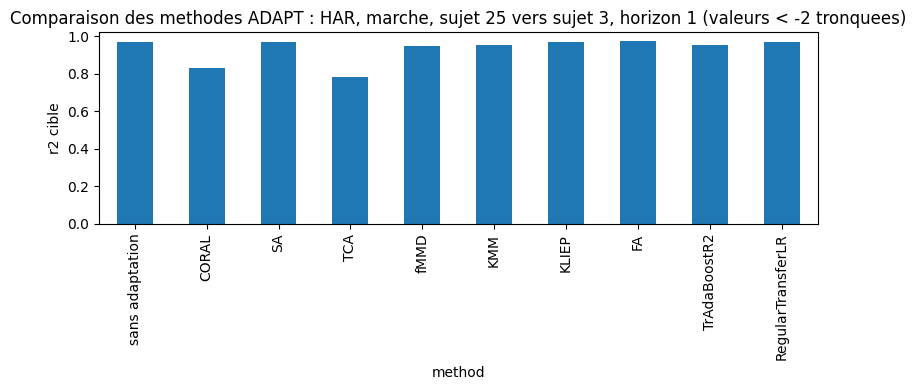

In [23]:
plot_floor = -2

fig, ax = plt.subplots(figsize=(8, 4))
results_df.set_index("method")["r2_target"].clip(lower=plot_floor).plot(kind="bar", ax=ax)
ax.set_ylabel("r2 cible")
ax.set_title(f"Comparaison des methodes ADAPT : HAR, marche, sujet 25 vers sujet 3, horizon {horizon} (valeurs < {plot_floor} tronquees)")
plt.tight_layout()
plt.show()

## Source vs cible

In [24]:
results_df[["method", "r2_source", "r2_target"]]

,method,r2_source,r2_target
0,sans adaptation,0.974283,0.967770
1,CORAL,0.974283,0.831970
2,SA,0.974283,0.967724
3,TCA,0.821910,0.785816
4,fMMD,0.964698,0.946671
5,KMM,0.966845,0.954339
6,KLIEP,0.974287,0.967779
7,FA,0.974279,0.972661
8,TrAdaBoostR2,0.944137,0.954953
9,RegularTransferLR,0.972693,0.970779
